EfficientDet model loaded successfully!


Saving pexels-photo-13782622.avif to pexels-photo-13782622 (2).avif
Object detection completed successfully!


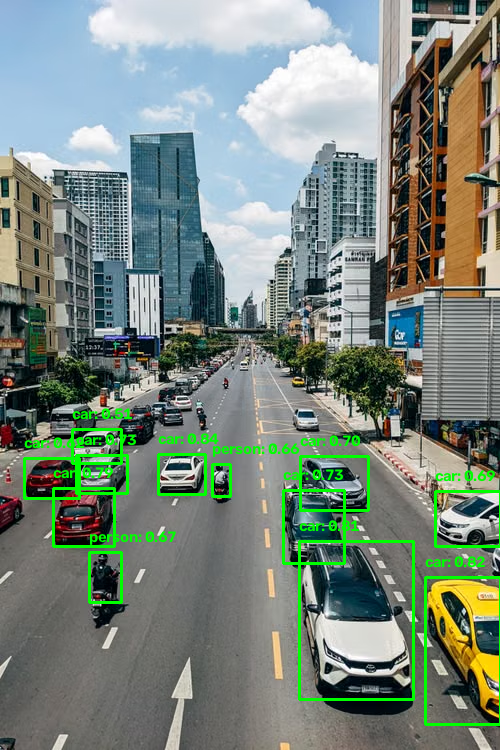

In [4]:

try:
    import pillow_heif
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pillow-heif"])
    import pillow_heif

import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2
from PIL import Image
from google.colab import files
from google.colab.patches import cv2_imshow


pillow_heif.register_heif_opener()


MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d7/1"
detector = hub.load(MODEL_URL)

print("EfficientDet model loaded successfully!")


COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus",
    "train", "truck", "boat", "traffic light", "fire hydrant",
    "stop sign", "parking meter", "bench", "bird", "cat", "dog",
    "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe",
    "backpack", "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat",
    "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl",
    "banana", "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "TV",
    "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]


def detect_objects_with_boxes(image_path, detector):


    try:
        pil_img = Image.open(image_path).convert("RGB")

        image = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)
    except Exception as e:

        image = cv2.imread(image_path)

    if image is None:
        raise ValueError("Could not read the image. Please upload a valid image.")

    orig_image = image.copy()


    input_tensor = tf.convert_to_tensor(image)
    input_tensor = input_tensor[tf.newaxis, ...]


    detections = detector(input_tensor)


    num_detections = int(detections["num_detections"].numpy()[0])
    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = (
        detections["detection_classes"].numpy()[0].astype(np.int32)
    )
    detection_scores = detections["detection_scores"].numpy()[0]


    confidence_threshold = 0.5

    h, w, _ = orig_image.shape


    for i in range(num_detections):

        score = detection_scores[i]

        if score > confidence_threshold:

            box = detection_boxes[i]


            y_min, x_min, y_max, x_max = box

            x_min = int(x_min * w)
            x_max = int(x_max * w)
            y_min = int(y_min * h)
            y_max = int(y_max * h)


            class_id = detection_classes[i]

            if 1 <= class_id <= len(COCO_CLASSES):
                class_name = COCO_CLASSES[class_id - 1]
            else:
                class_name = "Unknown"

            label = f"{class_name}: {score:.2f}"


            cv2.rectangle(
                orig_image,
                (x_min, y_min),
                (x_max, y_max),
                (0, 255, 0),
                2
            )


            cv2.putText(
                orig_image,
                label,
                (x_min, max(y_min - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

    return orig_image



uploaded = files.upload()

image_path = next(iter(uploaded))

result_image = detect_objects_with_boxes(image_path, detector)

print("Object detection completed successfully!")

cv2_imshow(result_image)